# Springboard EIA Graphing
Purpose is to demonstrate the relationship between various measures of price, supply, demand of crude oil and related products.  I choose weekly data from U.S. Energy Information Administration (EIA).

In [1]:
from pathlib import Path
import importlib
import oil_charts as charts
importlib.reload(charts)  # Reload the repaired script if the notebook was already open.

WORKBOOK = Path(r"C:\Users\sethp\Documents\S Pomeroy - AI & Data Science\Springboard\2) Course Units\Units 24 - Unit 33 - Advanced Phase\Springboard - Data Storytelling V3 (01 20 26).xlsx")
data = charts.load_data(WORKBOOK, include_derived=True)
print("Workbook:", WORKBOOK.name)
print("Weekly rows:", len(data))
data.head()


Workbook: Springboard - Data Storytelling V3 (01 20 26).xlsx
Weekly rows: 1137


,crude_inventory,gasoline_inventory,distillate_inventory,jet_inventory,new_england_distillate_inventory,wti_price,gasoline_price,diesel_price,jet_price,heating_oil_price,gasoline_consumption,distillate_consumption,jet_consumption
date,,,,,,,,,,,,,
2005-01-07,273060.0,215333.0,122980.0,40951.0,9724.0,44.07,1.778,1.957,1.228,1.922,8710.0,4172.0,1575.0
2005-01-14,276461.0,216969.0,123764.0,41622.0,10031.0,46.79,1.793,1.934,1.334,1.919,8695.0,4051.0,1517.0
2005-01-21,279890.0,214712.0,121485.0,42016.0,9319.0,47.85,1.819,1.952,1.375,1.939,8881.0,4462.0,1549.0
2005-01-28,279566.0,216342.0,118598.0,43068.0,8119.0,48.56,1.853,1.959,1.405,1.969,8848.0,4528.0,1545.0
2005-02-04,278156.0,216757.0,115607.0,43969.0,7715.0,46.97,1.911,1.992,1.287,1.992,8837.0,4378.0,1524.0


## Dates and a series
Inventory values are levels in thousand barrels. Prices have their own units.

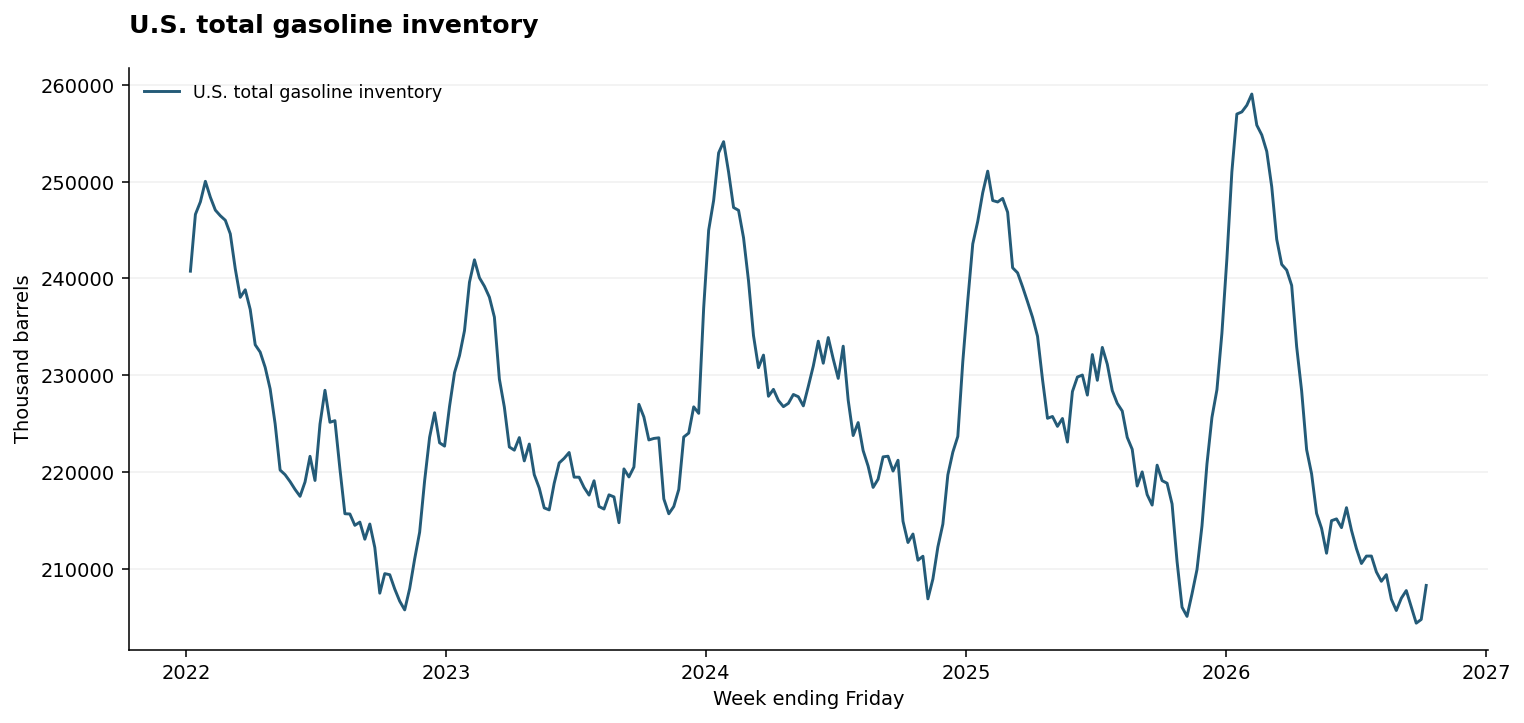

In [2]:
period = charts.select(data, "2022-01-01", "2026-10-16")
key = "gasoline_inventory"
fig = charts.line(period, [key], charts.LABELS[key], y_title=charts.UNITS[key])
charts.show(fig)


## Inventory and price comparison
Indexing discloses a common base date and compares relative movement.

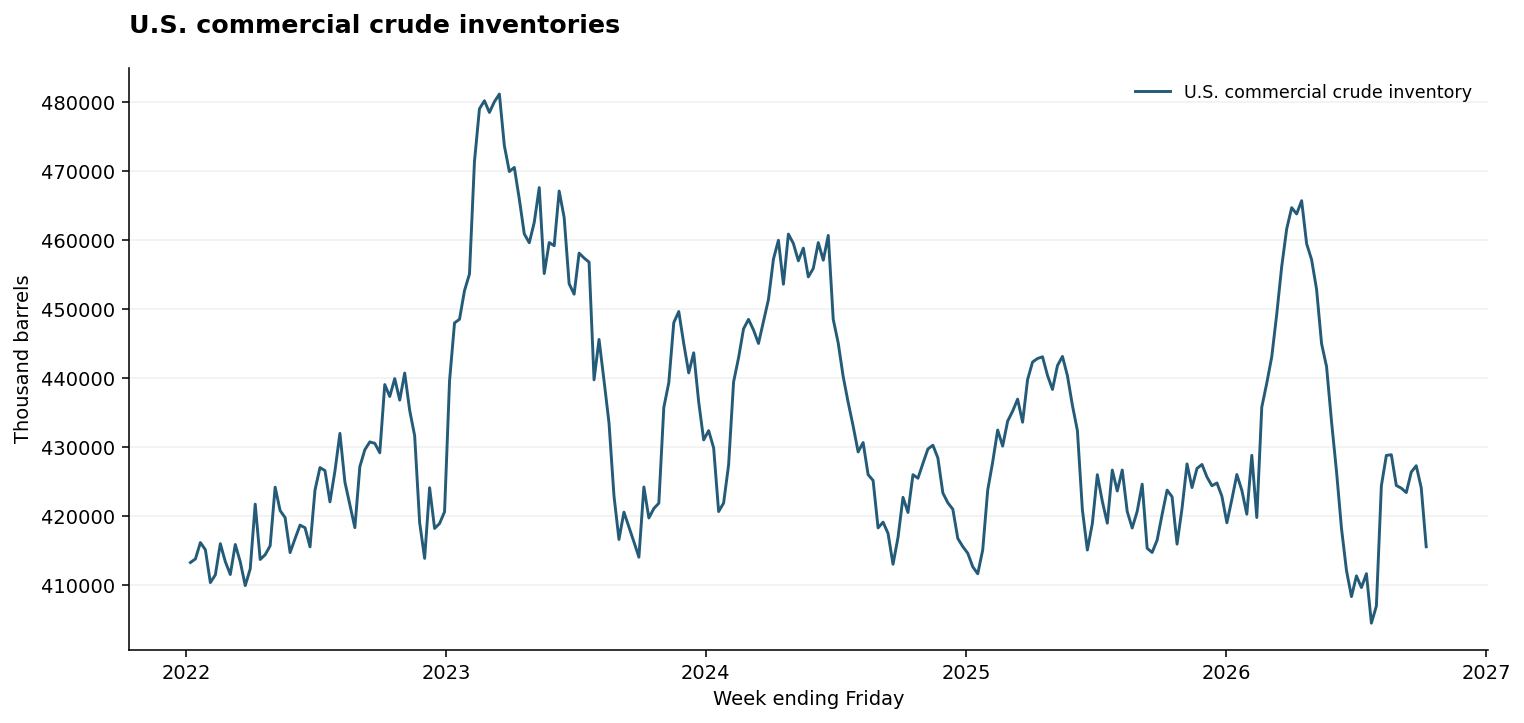

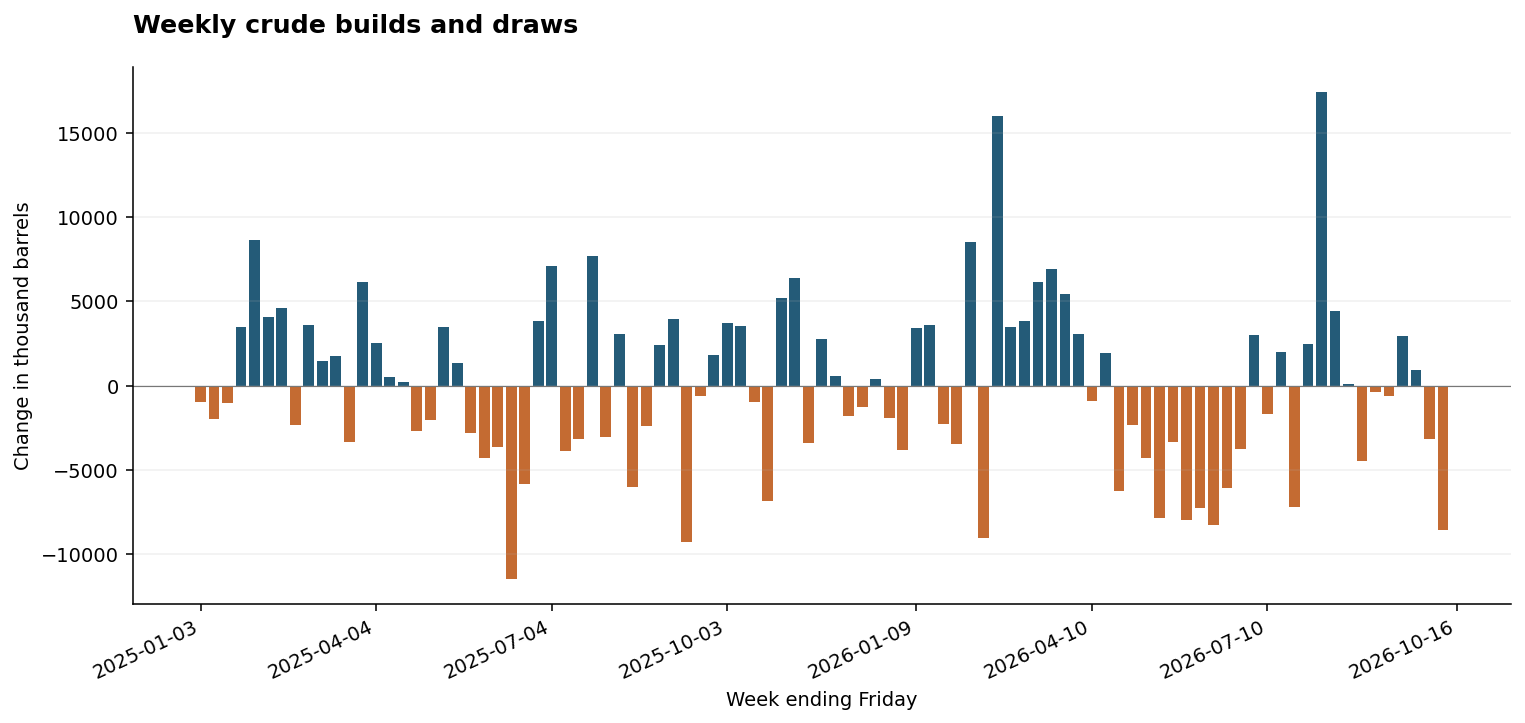

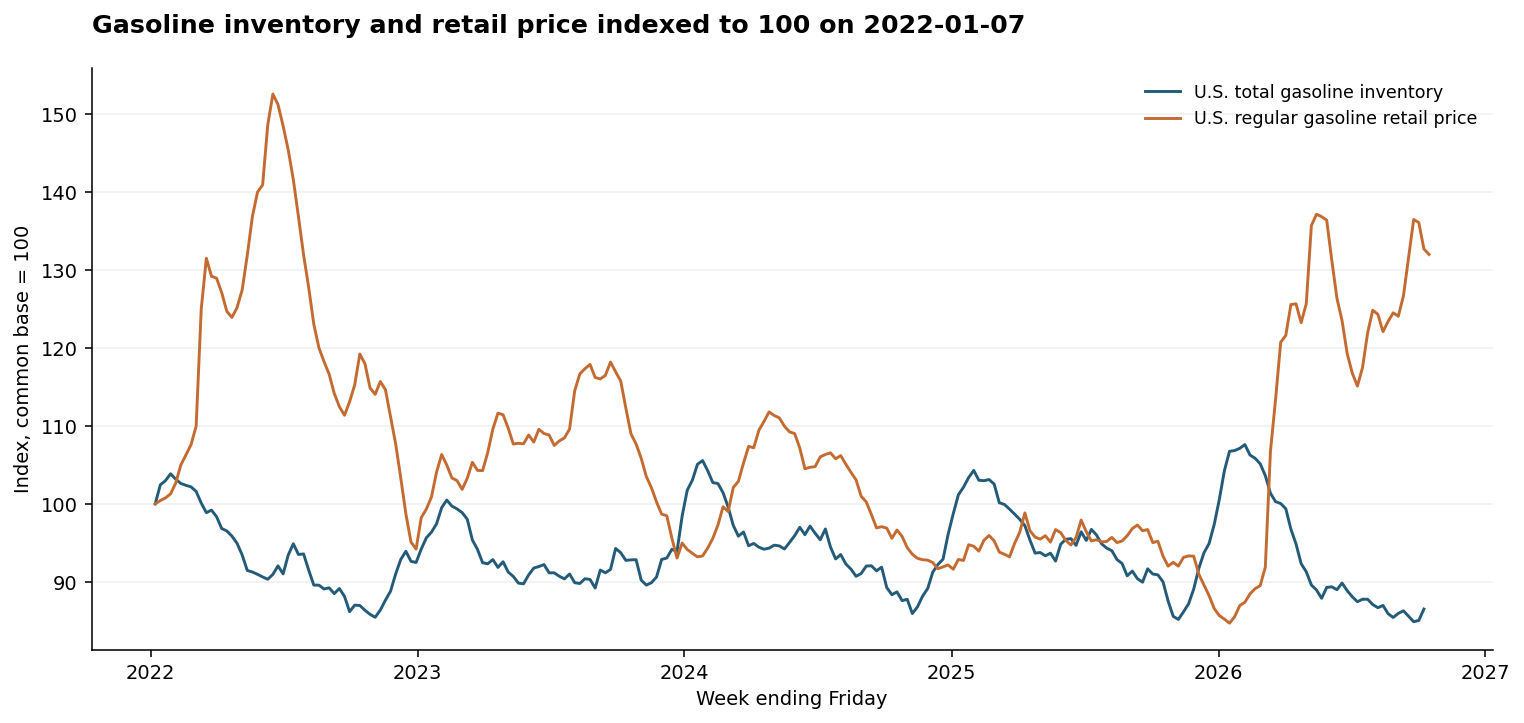

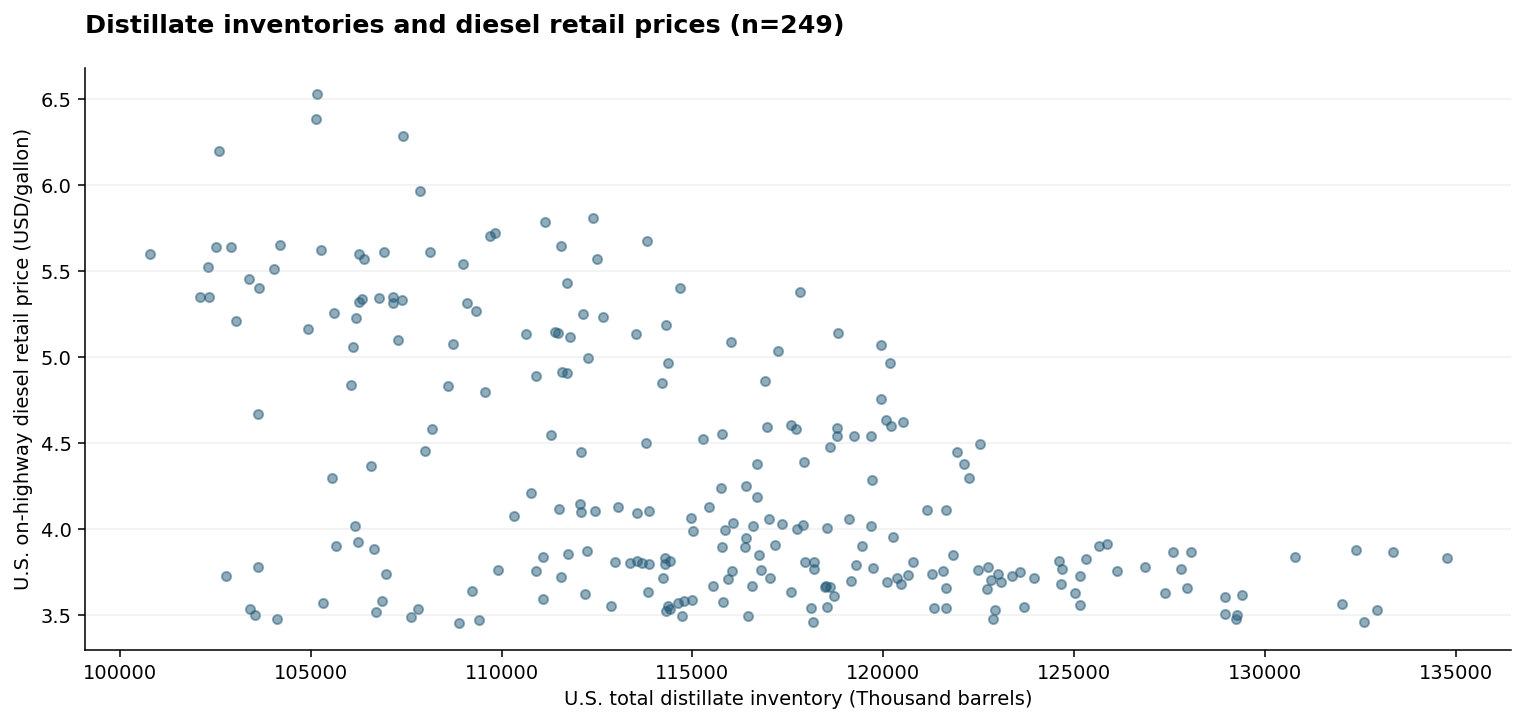

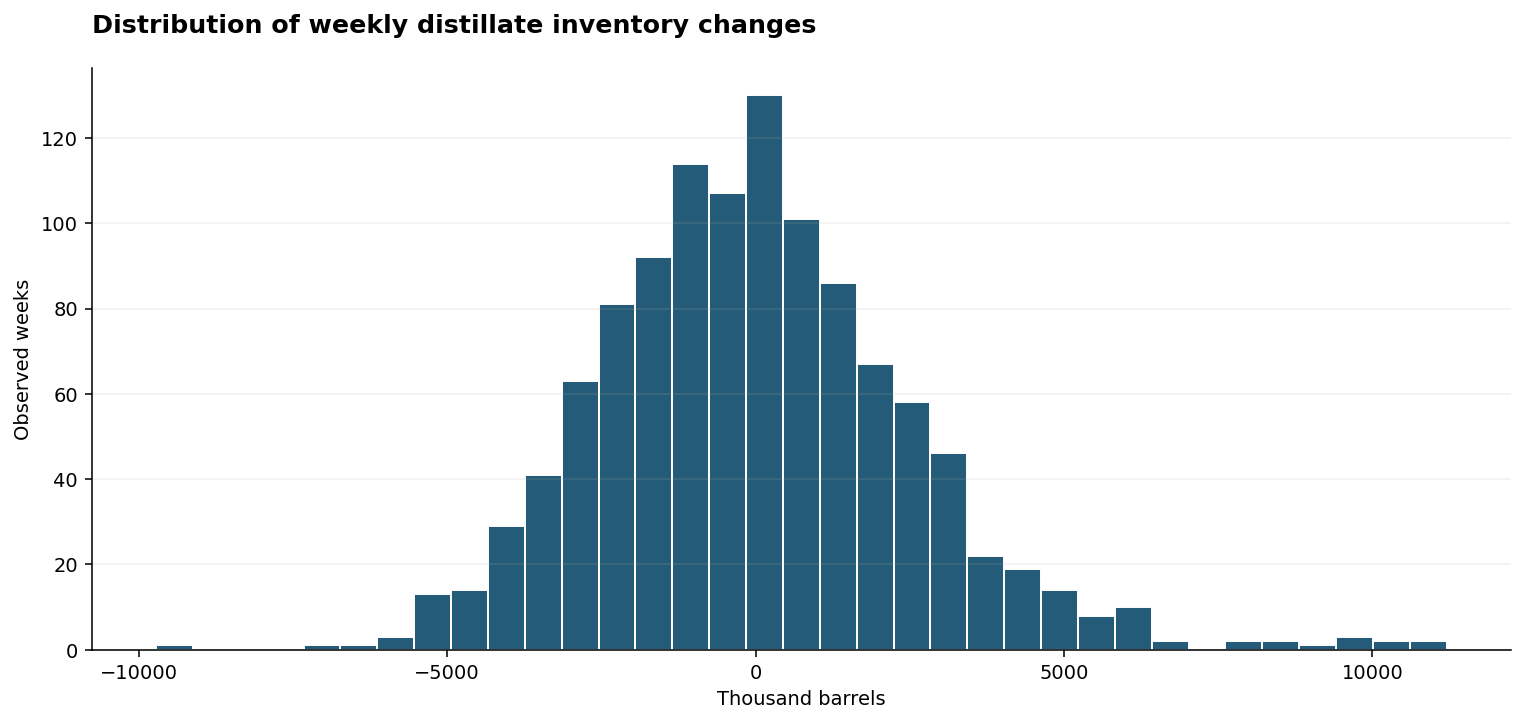

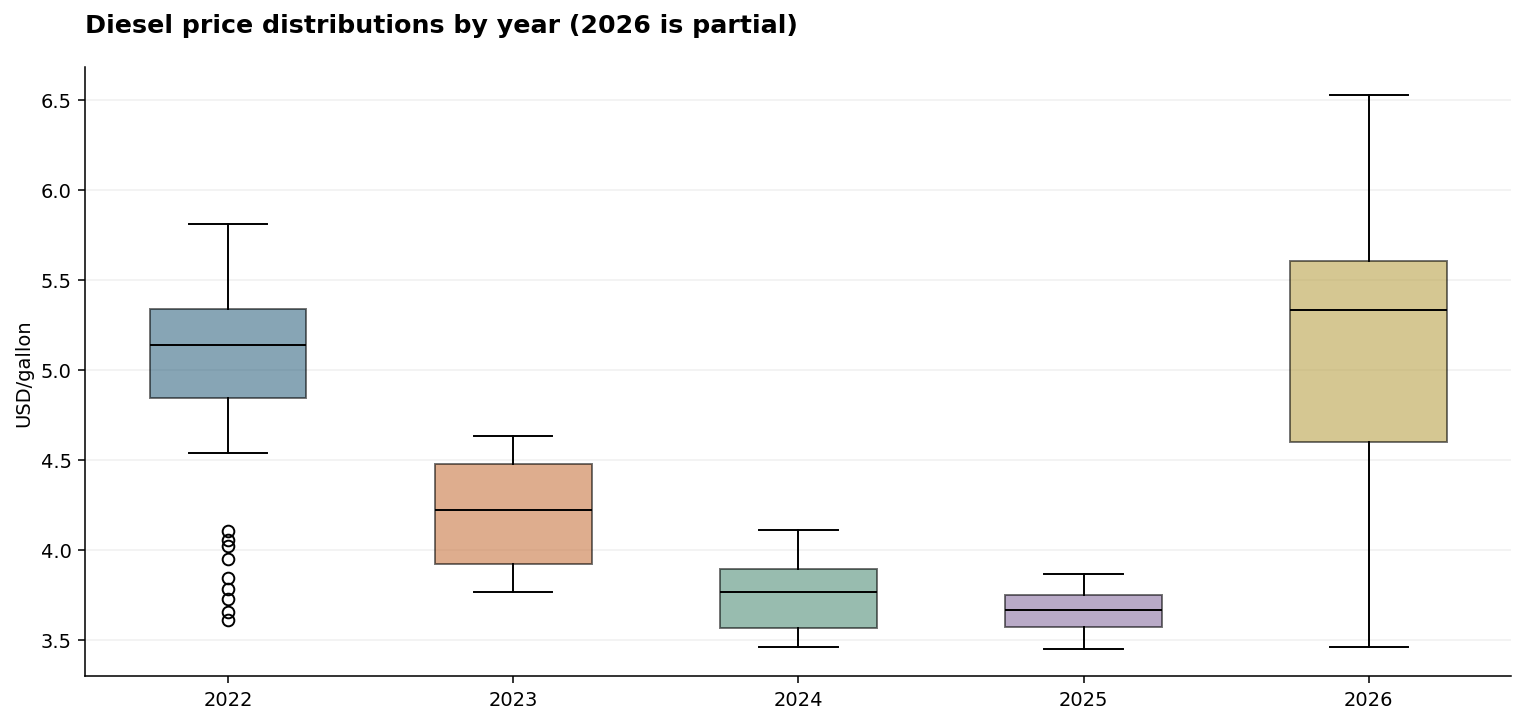

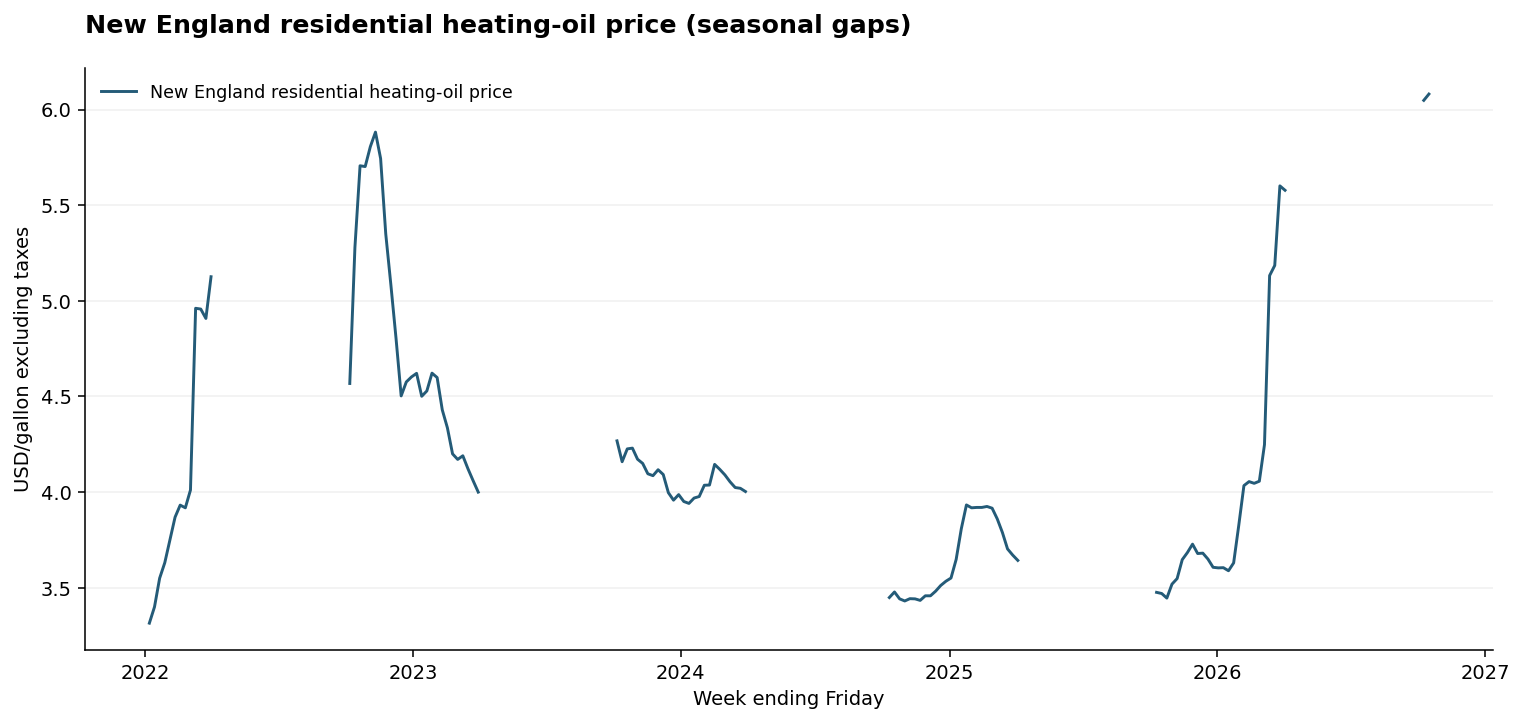

In [3]:
for fig in charts.examples(data)[:-1]:
    charts.show(fig)

In [4]:
# Calculate from full 2005–2026 history before selecting the presentation window.
ANALYSIS_START = "2022-01-01"
ANALYSIS_END = "2026-10-09"
HORIZONS = (1, 2, 4, 8)
results, delay_summary = charts.tightness_analysis(
    data, horizons=HORIZONS, start=ANALYSIS_START, end=ANALYSIS_END,
    demand_weeks=4, baseline_years=5, season_window_days=14,
    min_observations=15,
)
print("V3 consumption coverage:")
display(data[charts.CONSUMPTION_KEYS].count().to_frame("Observed weeks"))


V3 consumption coverage:


,Observed weeks
gasoline_consumption,1136
distillate_consumption,1135
jet_consumption,1134


## Seasonal days of supply, weekly builds/draws and seasonal deviations
Each product has its own scale and consumption denominator. Missing demand invalidates the four-week calculation; values are not filled.


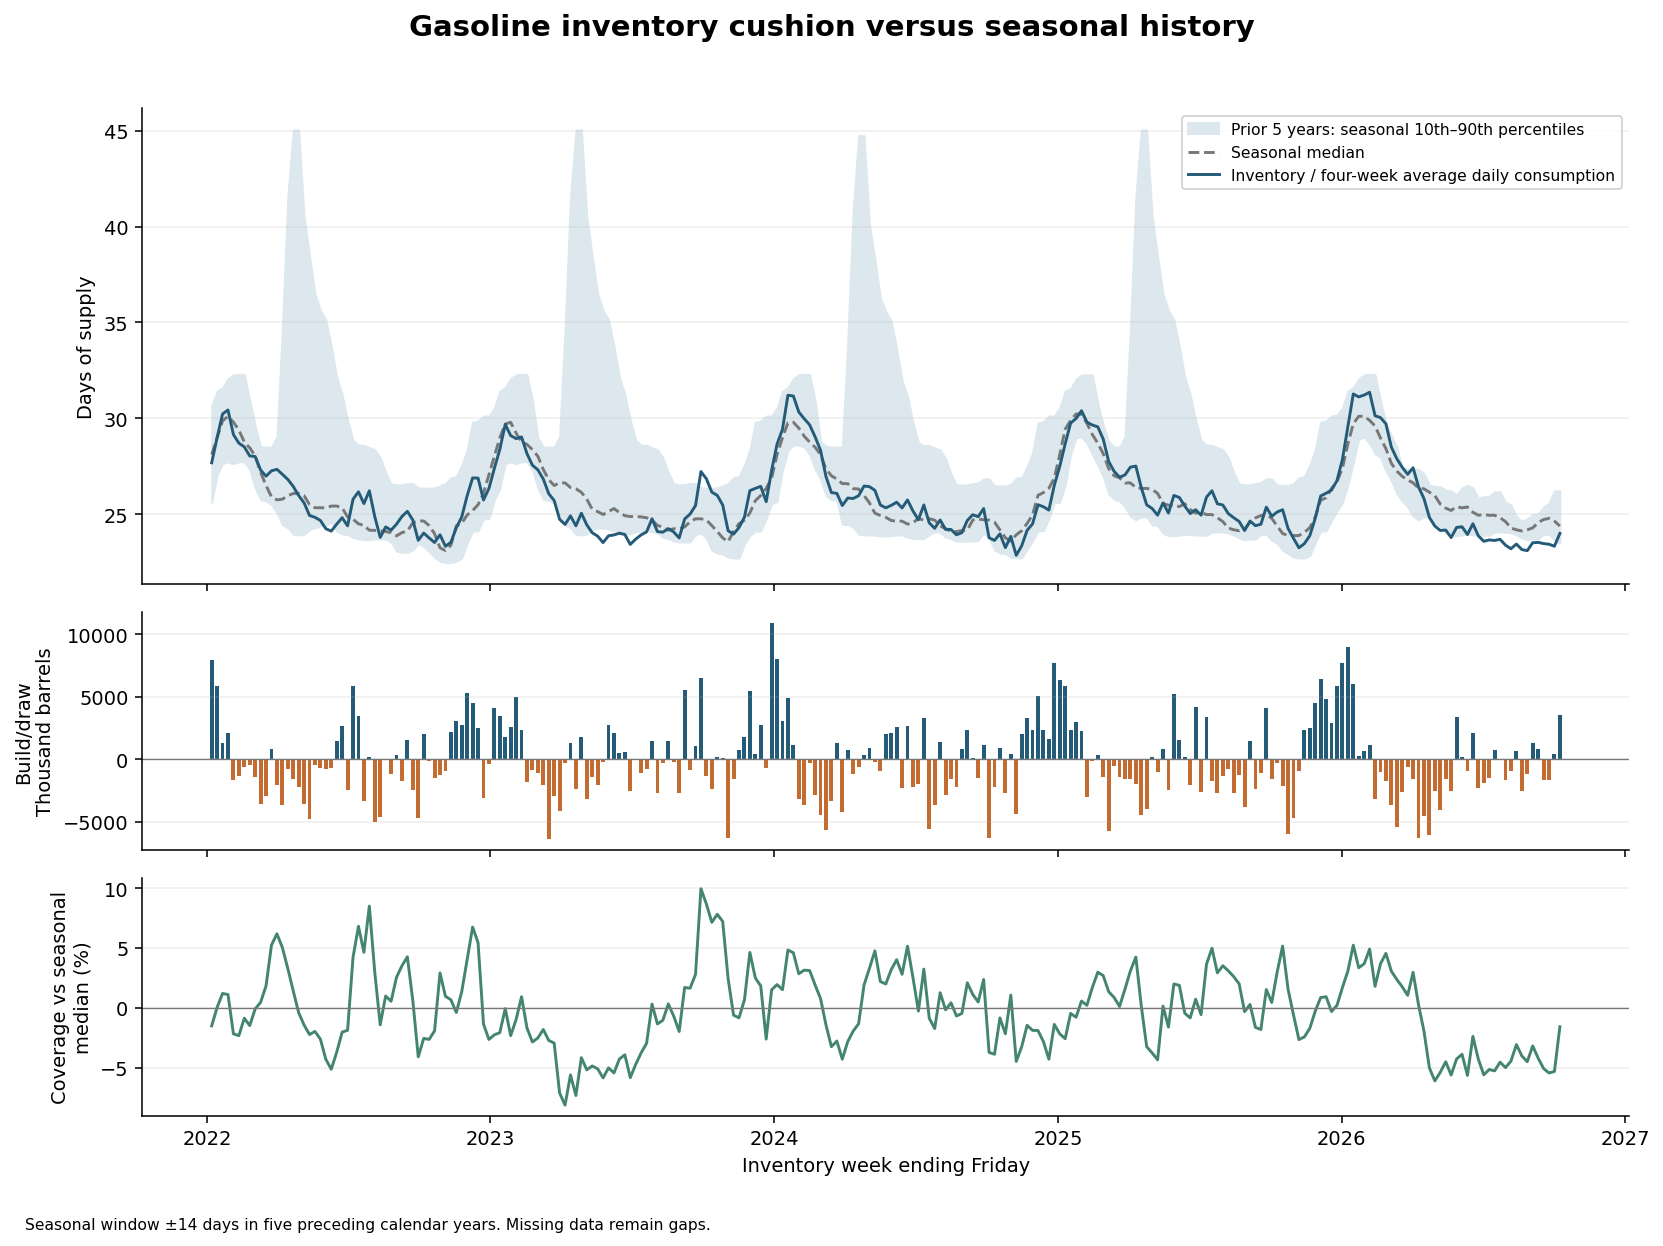

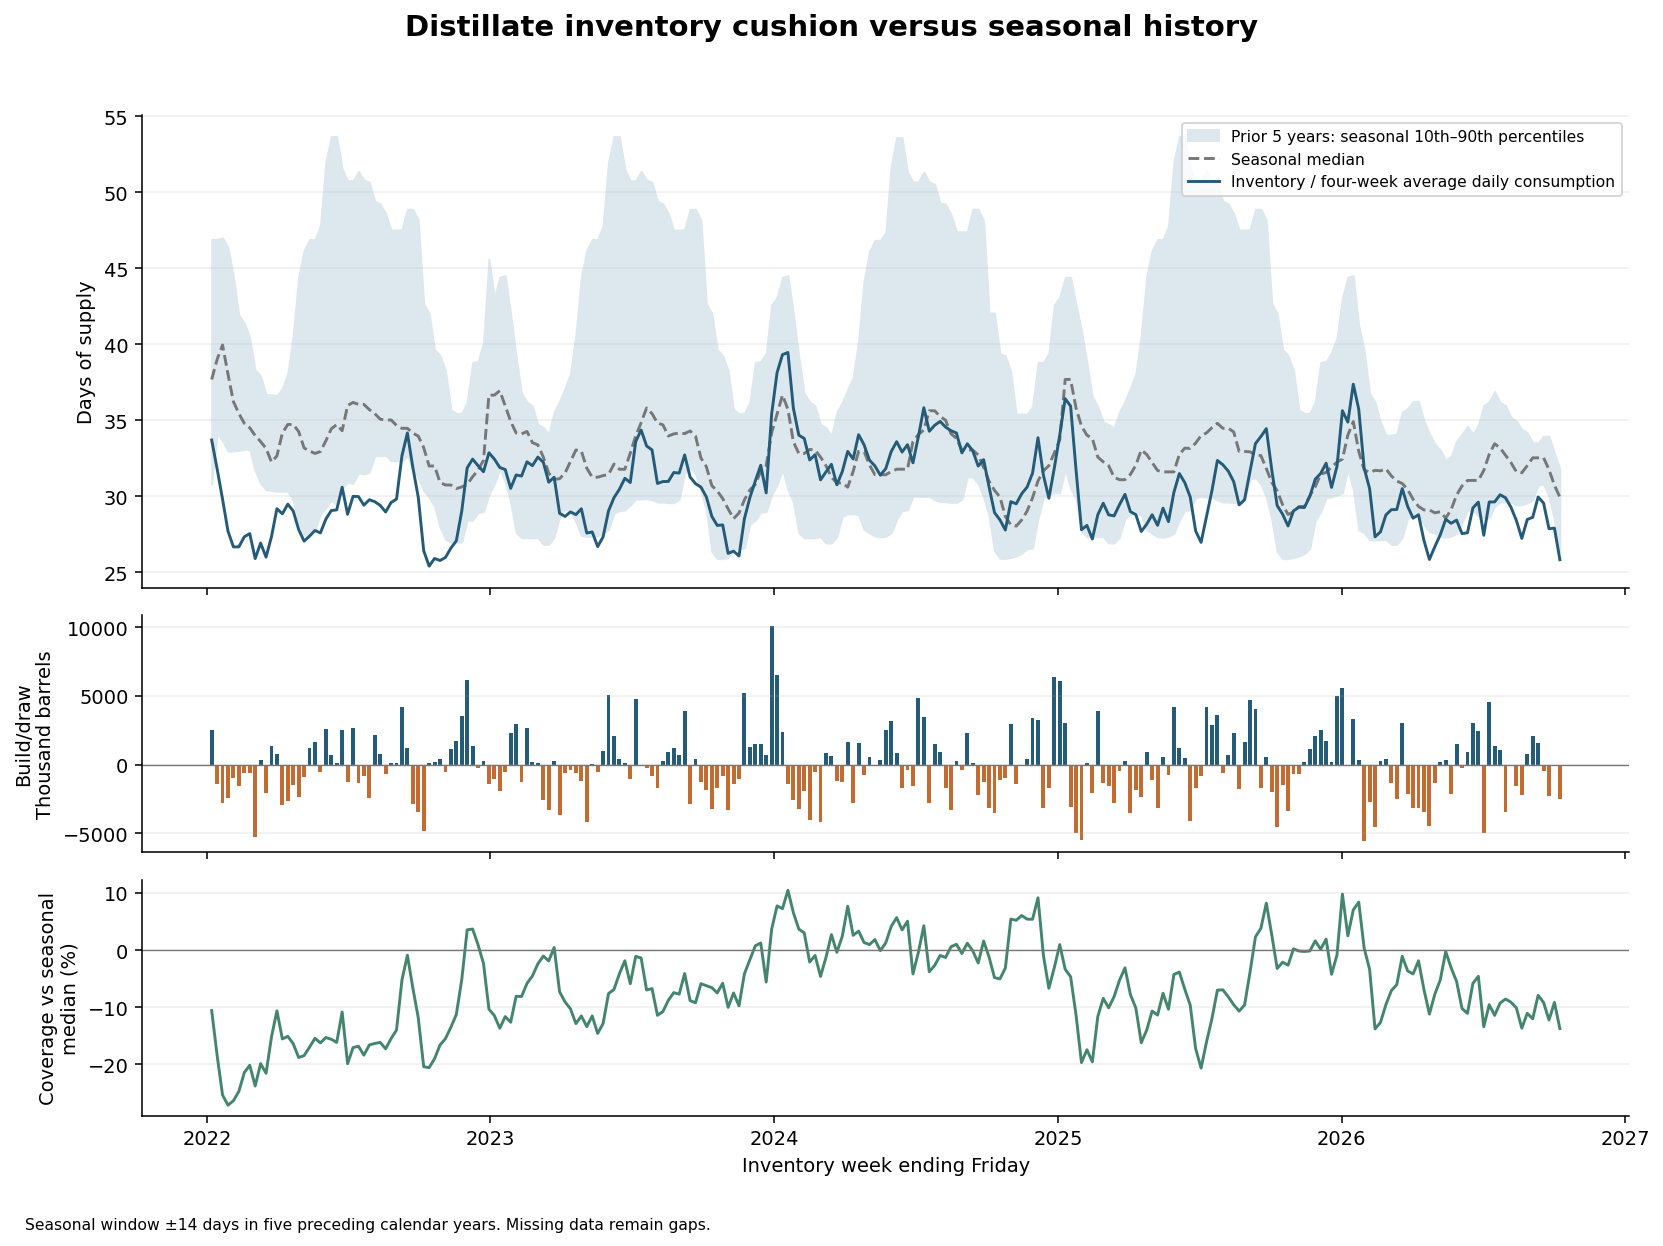

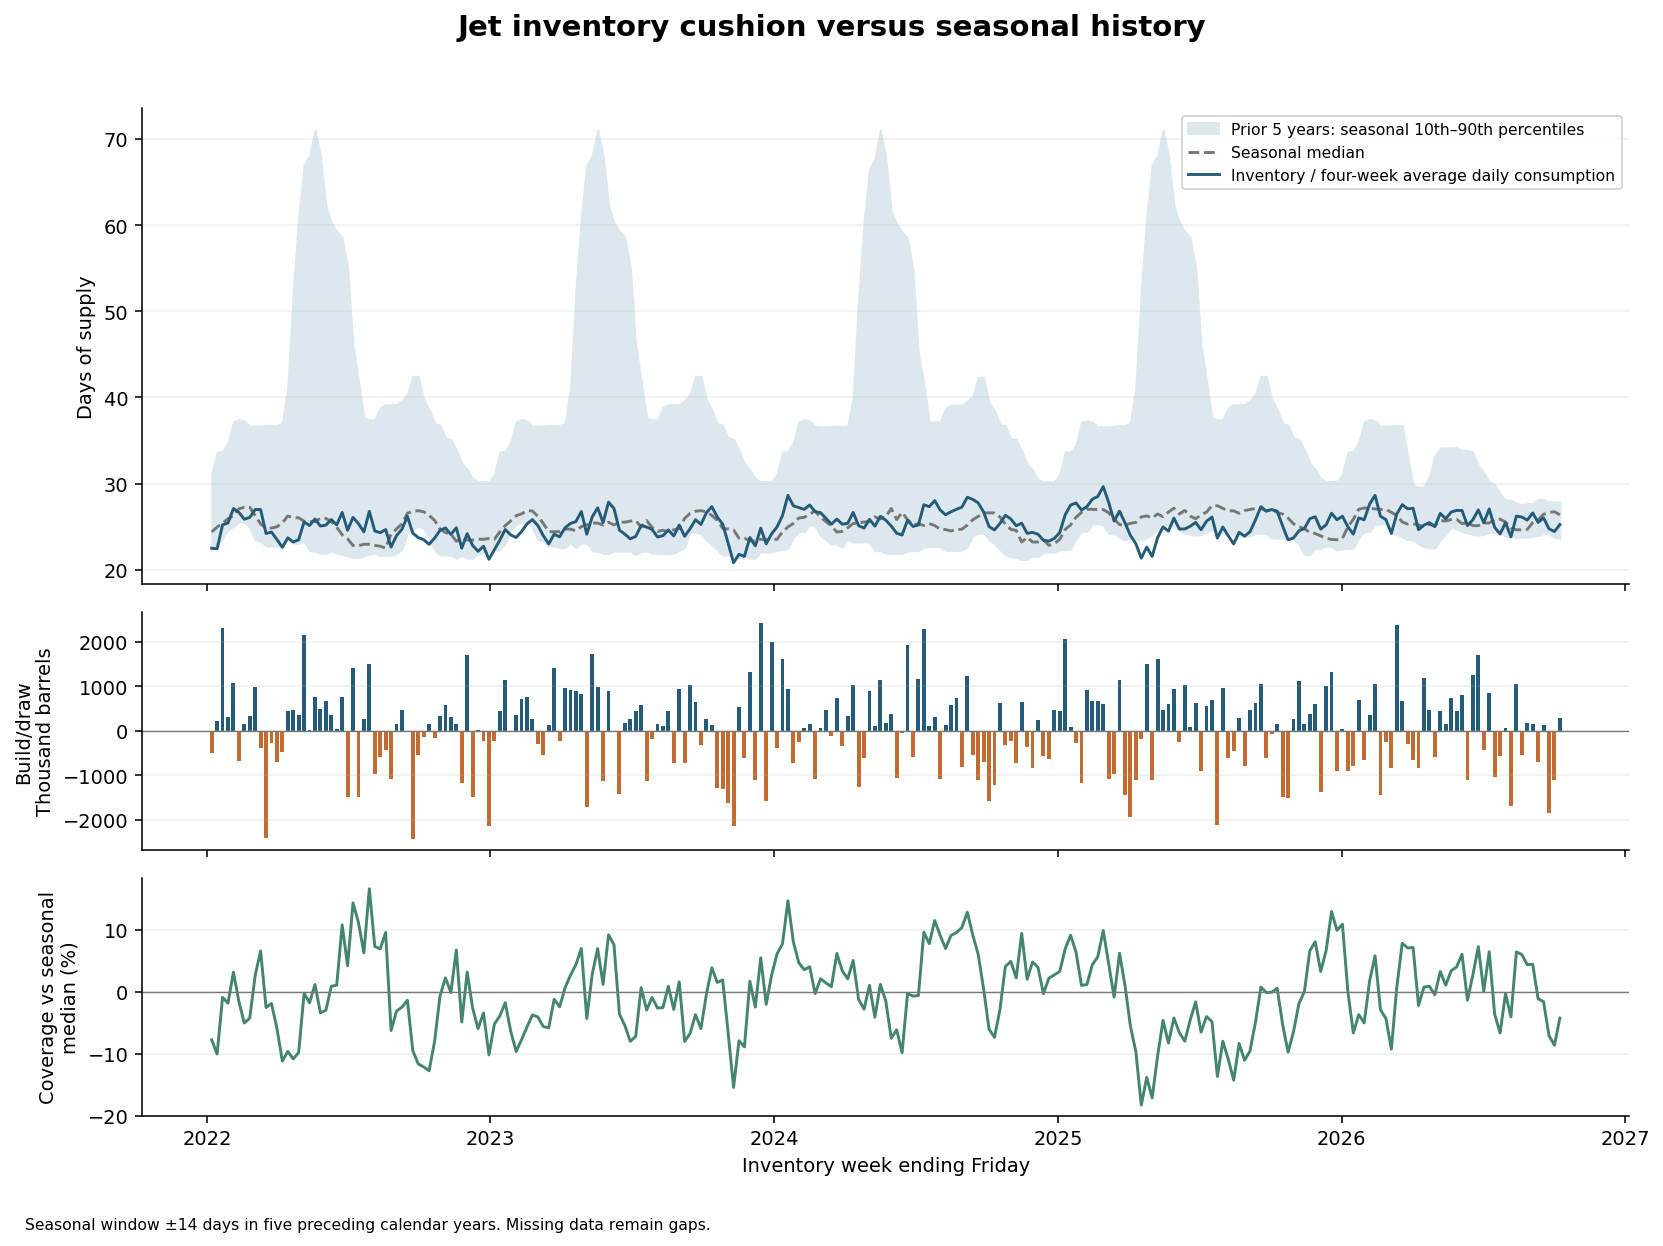

In [5]:
for product, calculation in results.items():
    charts.show_native(charts.tightness_chart(calculation, product,
        start=ANALYSIS_START, end=ANALYSIS_END))


## Price timing and delayed changes
The price in an existing Friday row is the Monday survey **four days earlier**, not a Friday price. For gasoline/diesel, the starting price is the first following Monday (inventory Friday +3 days), found in the next Friday row. The targets are exactly 1, 2, 4 and 8 weeks after that Monday. Jet fuel uses the first full Monday–Friday average after inventory Friday, followed by full averaging weeks at those delays.

Changes equal target price minus starting price. Percentage changes divide by the starting price. Baseline/target dates are shown below, even if their prices are unavailable. No missing week is replaced with the next available observation. Outcomes extending beyond the workbook remain missing.

These are **physical inventory-date comparisons**, not EIA-release event studies: the first Monday normally precedes the public inventory release. Publication dates, historical vintages and predictive validation would be needed for a trading or announcement-response interpretation. Weekly averages also cannot locate a response within a week.


In [6]:
timing_columns = ["inventory_week_ending", "preceding_retail_survey_date",
    "baseline_period_start", "baseline_period_end", "baseline_price",
    "target_start_1w", "target_end_1w", "target_price_1w", "price_change_1w",
    "target_start_4w", "target_price_4w", "price_change_pct_4w"]
display(results["distillate"][timing_columns].head(6))


,inventory_week_ending,preceding_retail_survey_date,baseline_period_start,baseline_period_end,baseline_price,target_start_1w,target_end_1w,target_price_1w,price_change_1w,target_start_4w,target_price_4w,price_change_pct_4w
date,,,,,,,,,,,,
2022-01-07,2022-01-07,2022-01-03,2022-01-10,2022-01-10,3.657,2022-01-17,2022-01-17,3.725,0.068,2022-02-07,3.951,8.039377
2022-01-14,2022-01-14,2022-01-10,2022-01-17,2022-01-17,3.725,2022-01-24,2022-01-24,3.780,0.055,2022-02-14,4.019,7.892617
2022-01-21,2022-01-21,2022-01-17,2022-01-24,2022-01-24,3.780,2022-01-31,2022-01-31,3.846,0.066,2022-02-21,4.055,7.275132
2022-01-28,2022-01-28,2022-01-24,2022-01-31,2022-01-31,3.846,2022-02-07,2022-02-07,3.951,0.105,2022-02-28,4.104,6.708268
2022-02-04,2022-02-04,2022-01-31,2022-02-07,2022-02-07,3.951,2022-02-14,2022-02-14,4.019,0.068,2022-03-07,4.849,22.728423
2022-02-11,2022-02-11,2022-02-07,2022-02-14,2022-02-14,4.019,2022-02-21,2022-02-21,4.055,0.036,2022-03-14,5.250,30.629510


## Added evidence: price levels, inventory cushions and the recent trend
This section preserves the earlier change-based analysis and asks a different question: **do thinner inventories or seasonal cushions accompany higher fuel price levels?** It also tests the direct **WTI price level versus fuel price level** relationship.

Fixed windows: full available history (2005 onward), the previous analysis window (2022 onward), and 2026. All windows end at inventory week October 9, 2026; sample endpoints and paired counts are disclosed. Seasonal coverage comparisons begin only when five preceding calendar years are available. We do not select peaks, troughs or starting dates to maximize correlations.

**Terminology:** a decline in stored inventory is not necessarily a decline in production or total supply. Days of supply relates stocks to recent domestic consumption. Claims of lower production, lower imports or supply disruption require those additional series. The figures supplied in chat do not establish that their gasoline benchmark is identical to our national retail series.

**Price alignment:** WTI is the weekly average ending on inventory Friday. Gasoline, diesel and heating oil use the following Monday survey; jet uses the following complete Monday–Friday spot average. Heating oil is seasonal. These are explicit near-contemporaneous physical-date comparisons, not release-date trading signals.


,period,fuel,pearson_r,paired_weeks,first_inventory_week,last_inventory_week,last_fuel_price_period_end
0,Full history,Gasoline,0.874,1136,2005-01-07,2026-10-09,2026-10-12
3,Earlier analysis window,Gasoline,0.907,249,2022-01-07,2026-10-09,2026-10-12
6,2026,Gasoline,0.915,41,2026-01-02,2026-10-09,2026-10-12
9,Full history,Diesel / total distillate,0.781,1136,2005-01-07,2026-10-09,2026-10-12
12,Earlier analysis window,Diesel / total distillate,0.826,249,2022-01-07,2026-10-09,2026-10-12
15,2026,Diesel / total distillate,0.897,41,2026-01-02,2026-10-09,2026-10-12
18,Full history,Jet fuel,0.912,1135,2005-01-07,2026-10-02,2026-10-09
21,Earlier analysis window,Jet fuel,0.820,248,2022-01-07,2026-10-02,2026-10-09
24,2026,Jet fuel,0.827,40,2026-01-02,2026-10-02,2026-10-09
27,Full history,Heating oil / New England distillate,0.744,531,2005-01-07,2026-10-09,2026-10-12


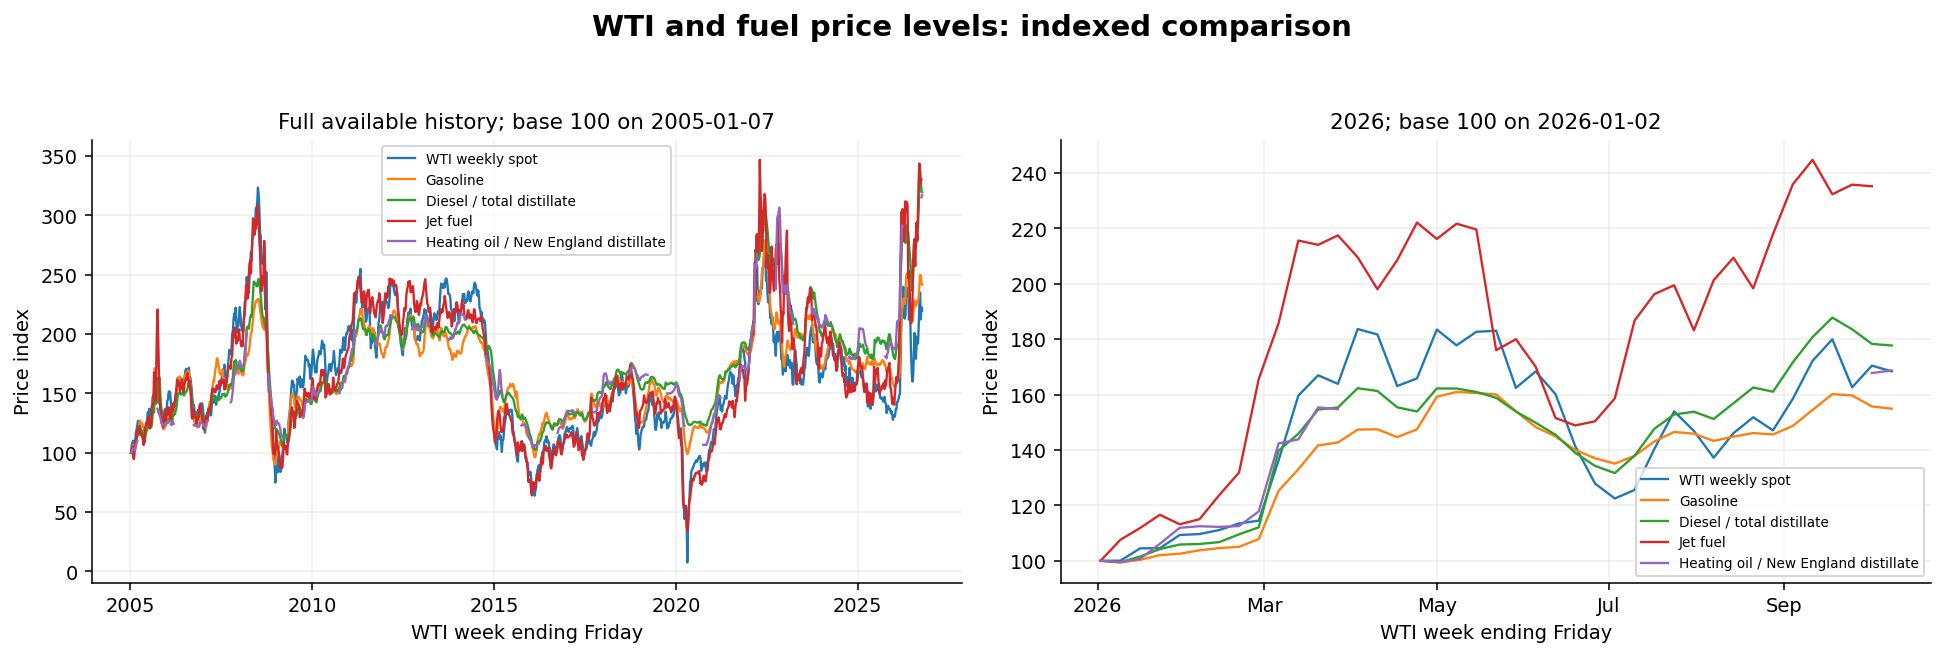

In [7]:
level_details, level_correlations = charts.price_level_evidence(data, end="2026-10-09")
wti_table = level_correlations.query("factor == 'WTI price level'")
display(wti_table[["period", "fuel", "pearson_r", "paired_weeks",
    "first_inventory_week", "last_inventory_week", "last_fuel_price_period_end"]].round({"pearson_r": 3}))
charts.show_native(charts.wti_fuel_level_panels(data))


## Inventory cushion and price levels, shown together
Full history and 2026 are side by side. Price and coverage have separate vertically aligned axes so the scales cannot be tuned to imply a match. Historical seasonal ranges include pandemic years. New England heating oil uses regional distillate inventory levels, not days of heating-oil supply, because the separate demand denominator is unavailable.


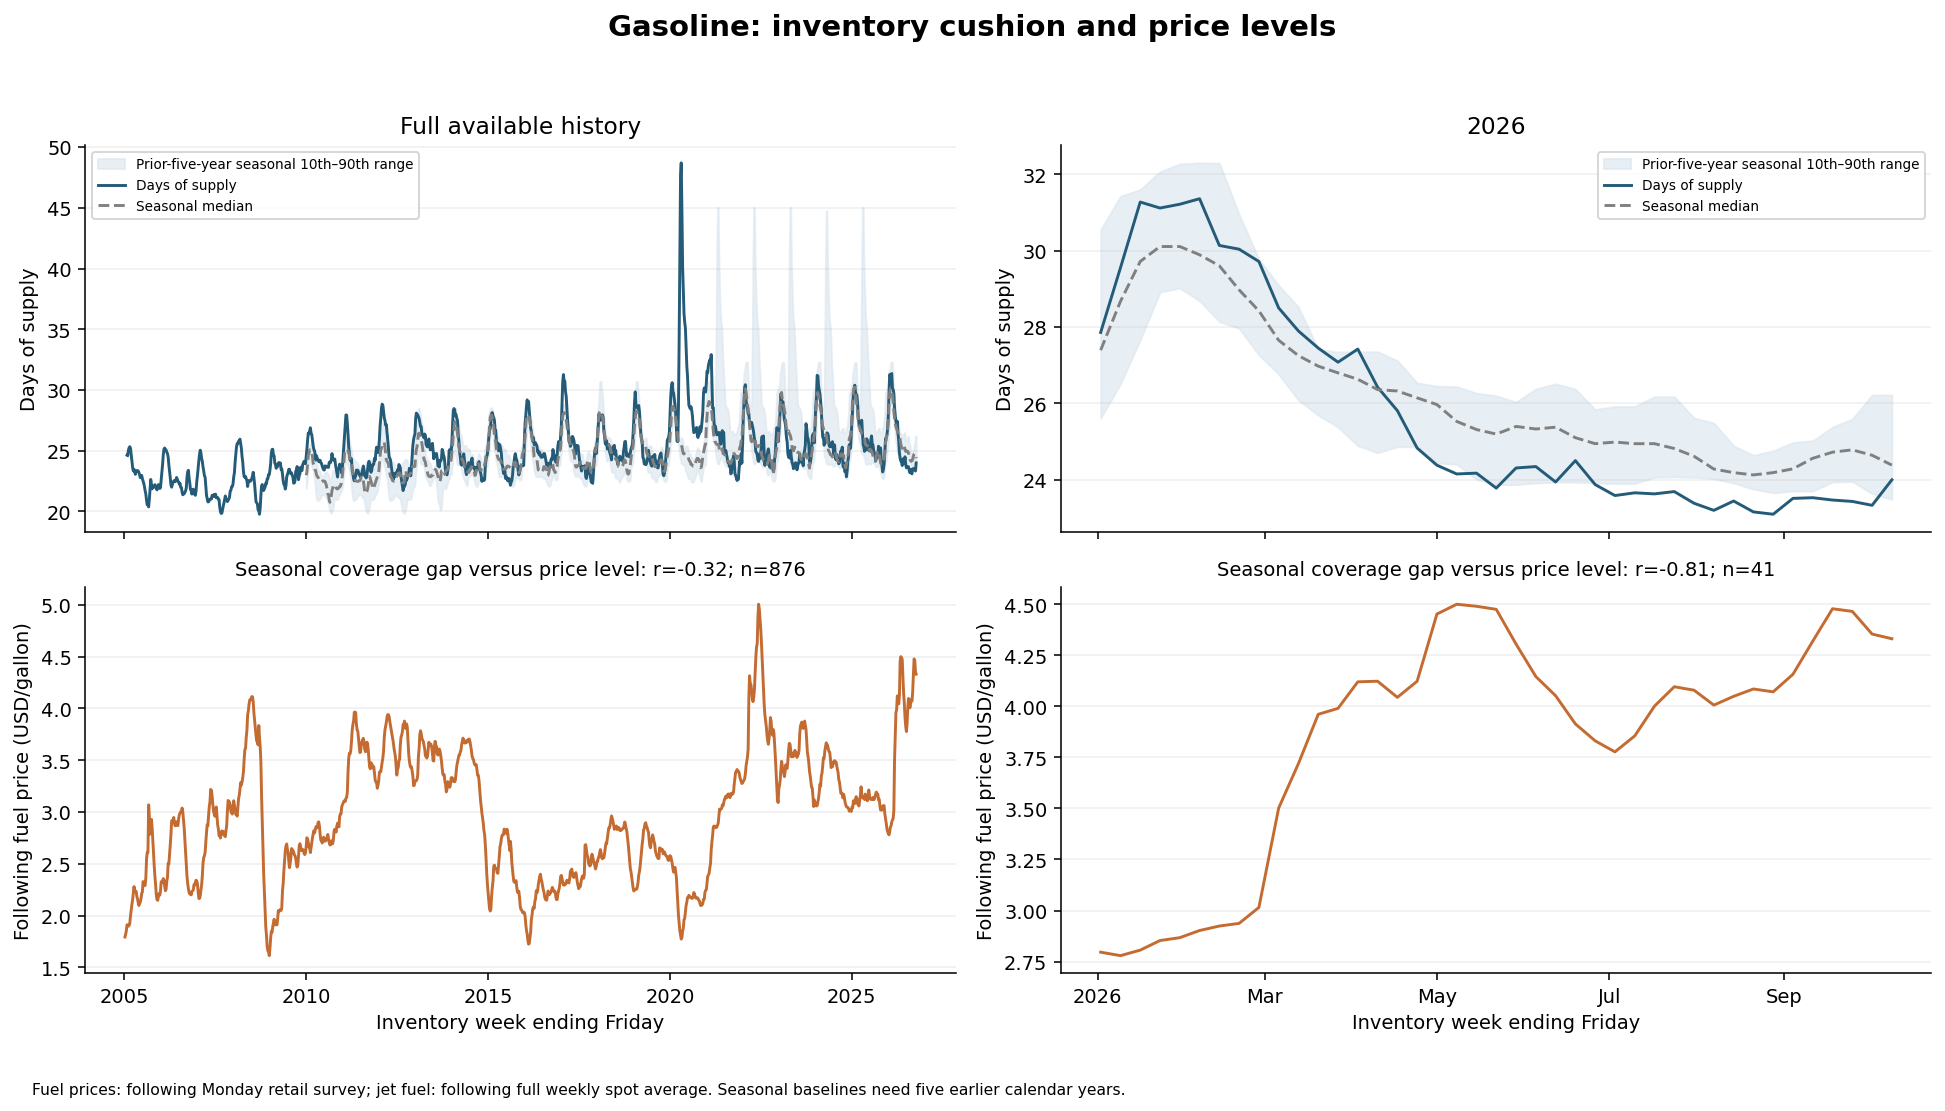

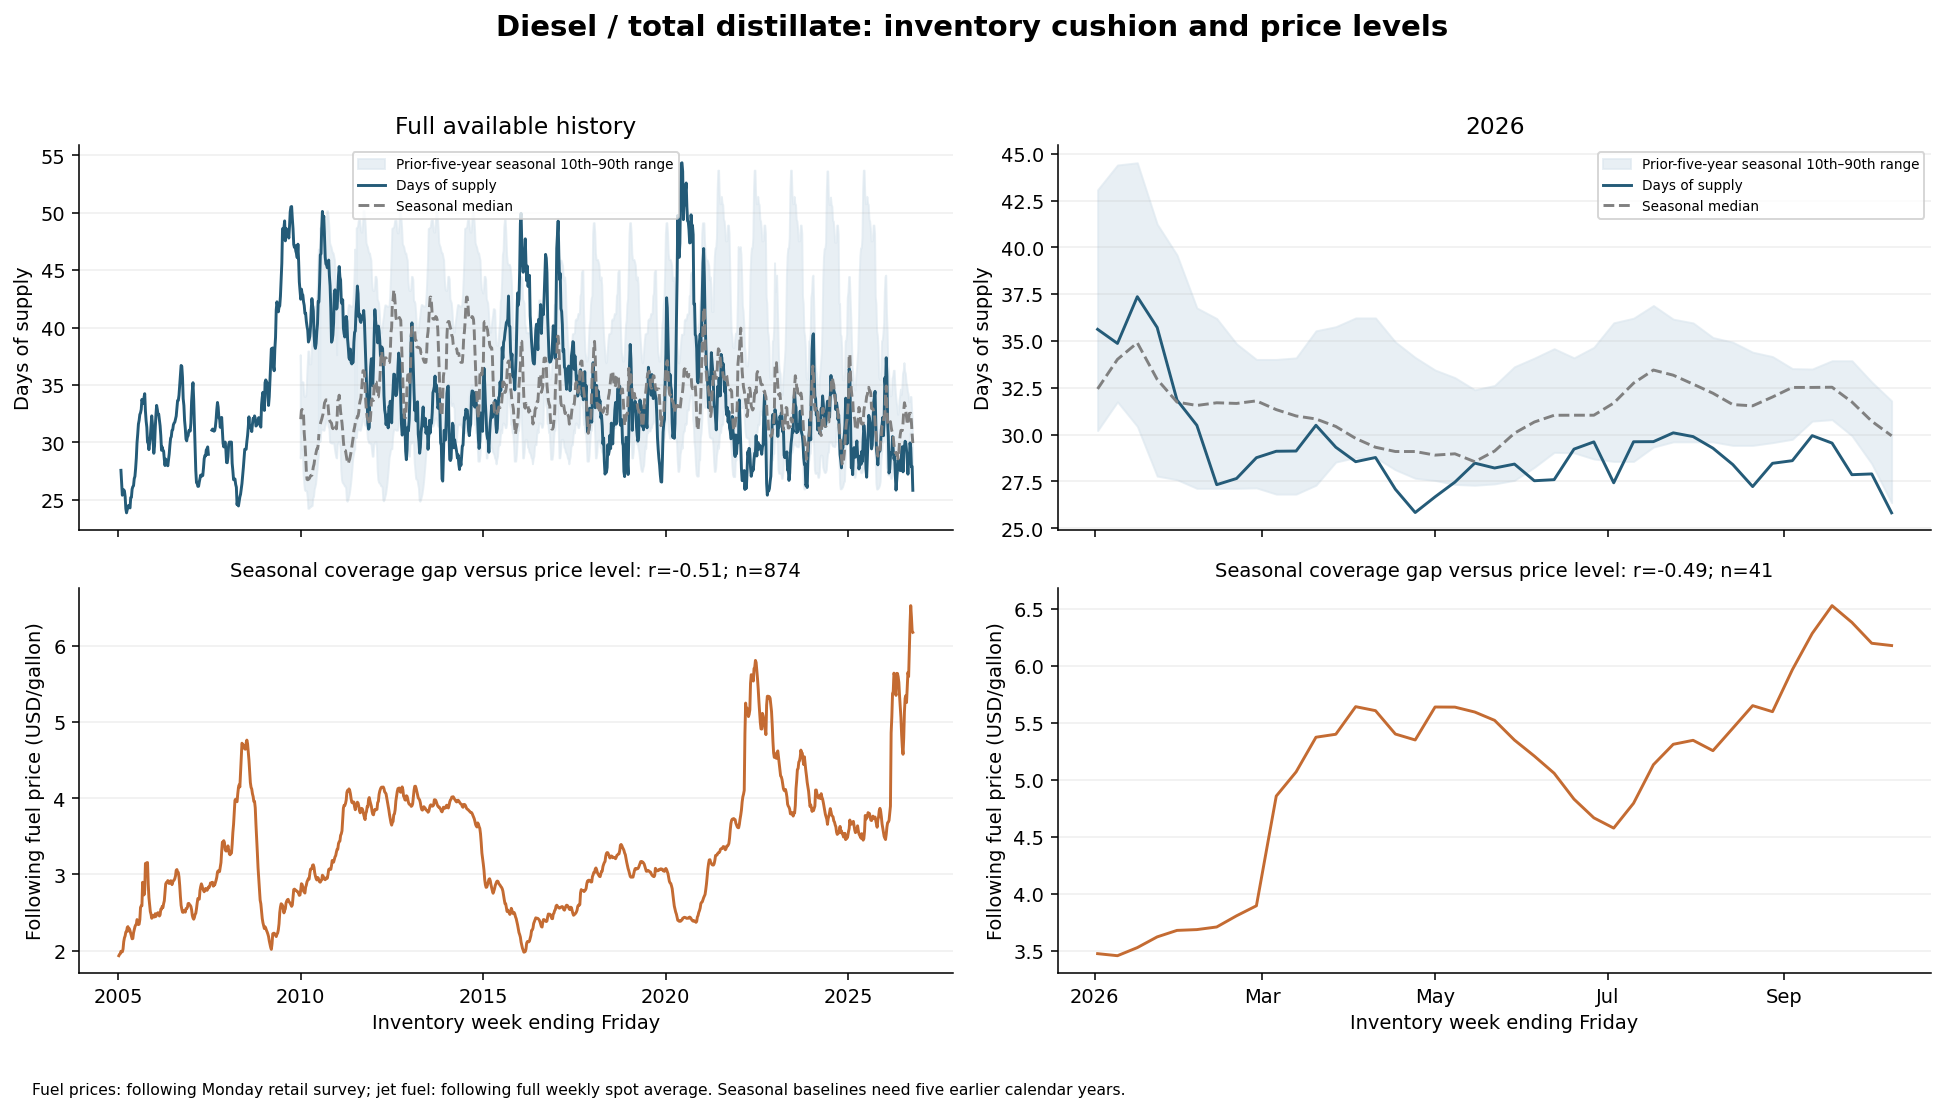

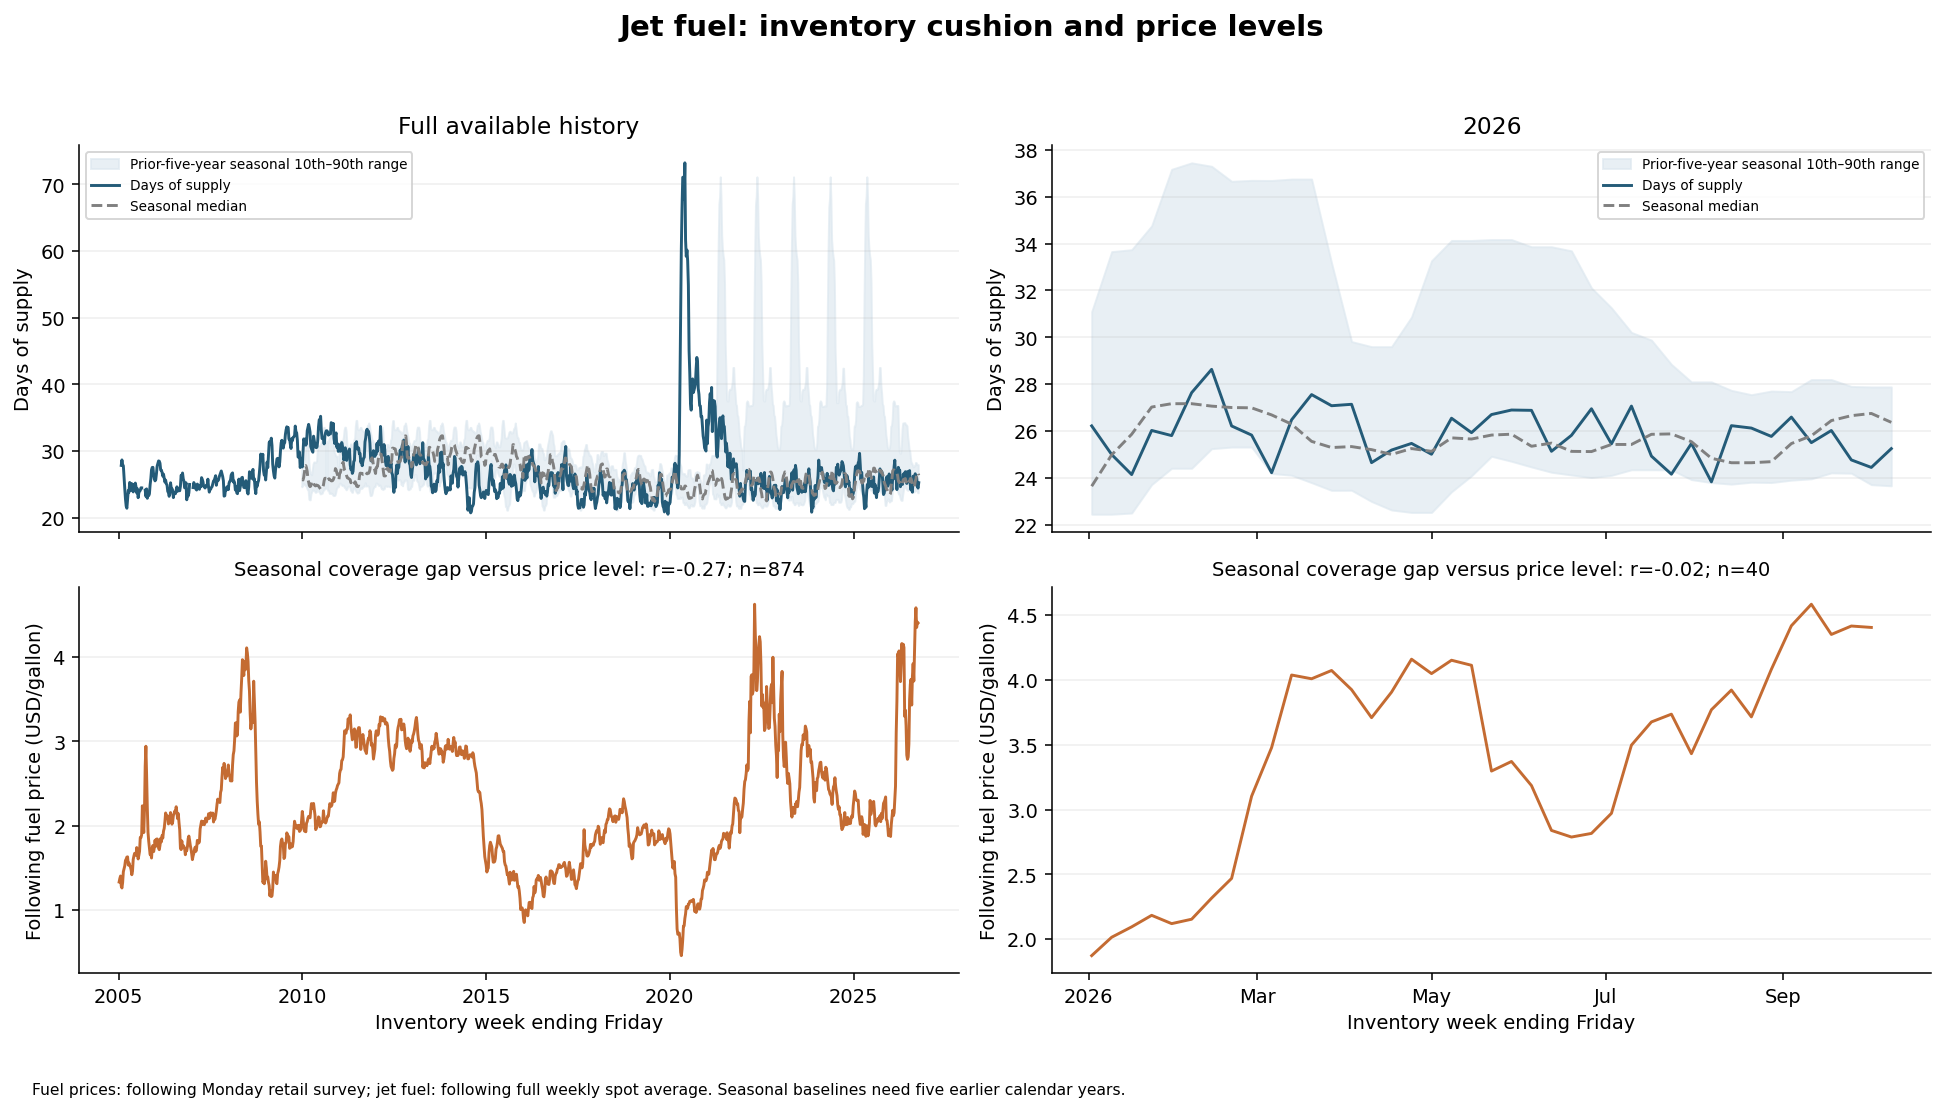

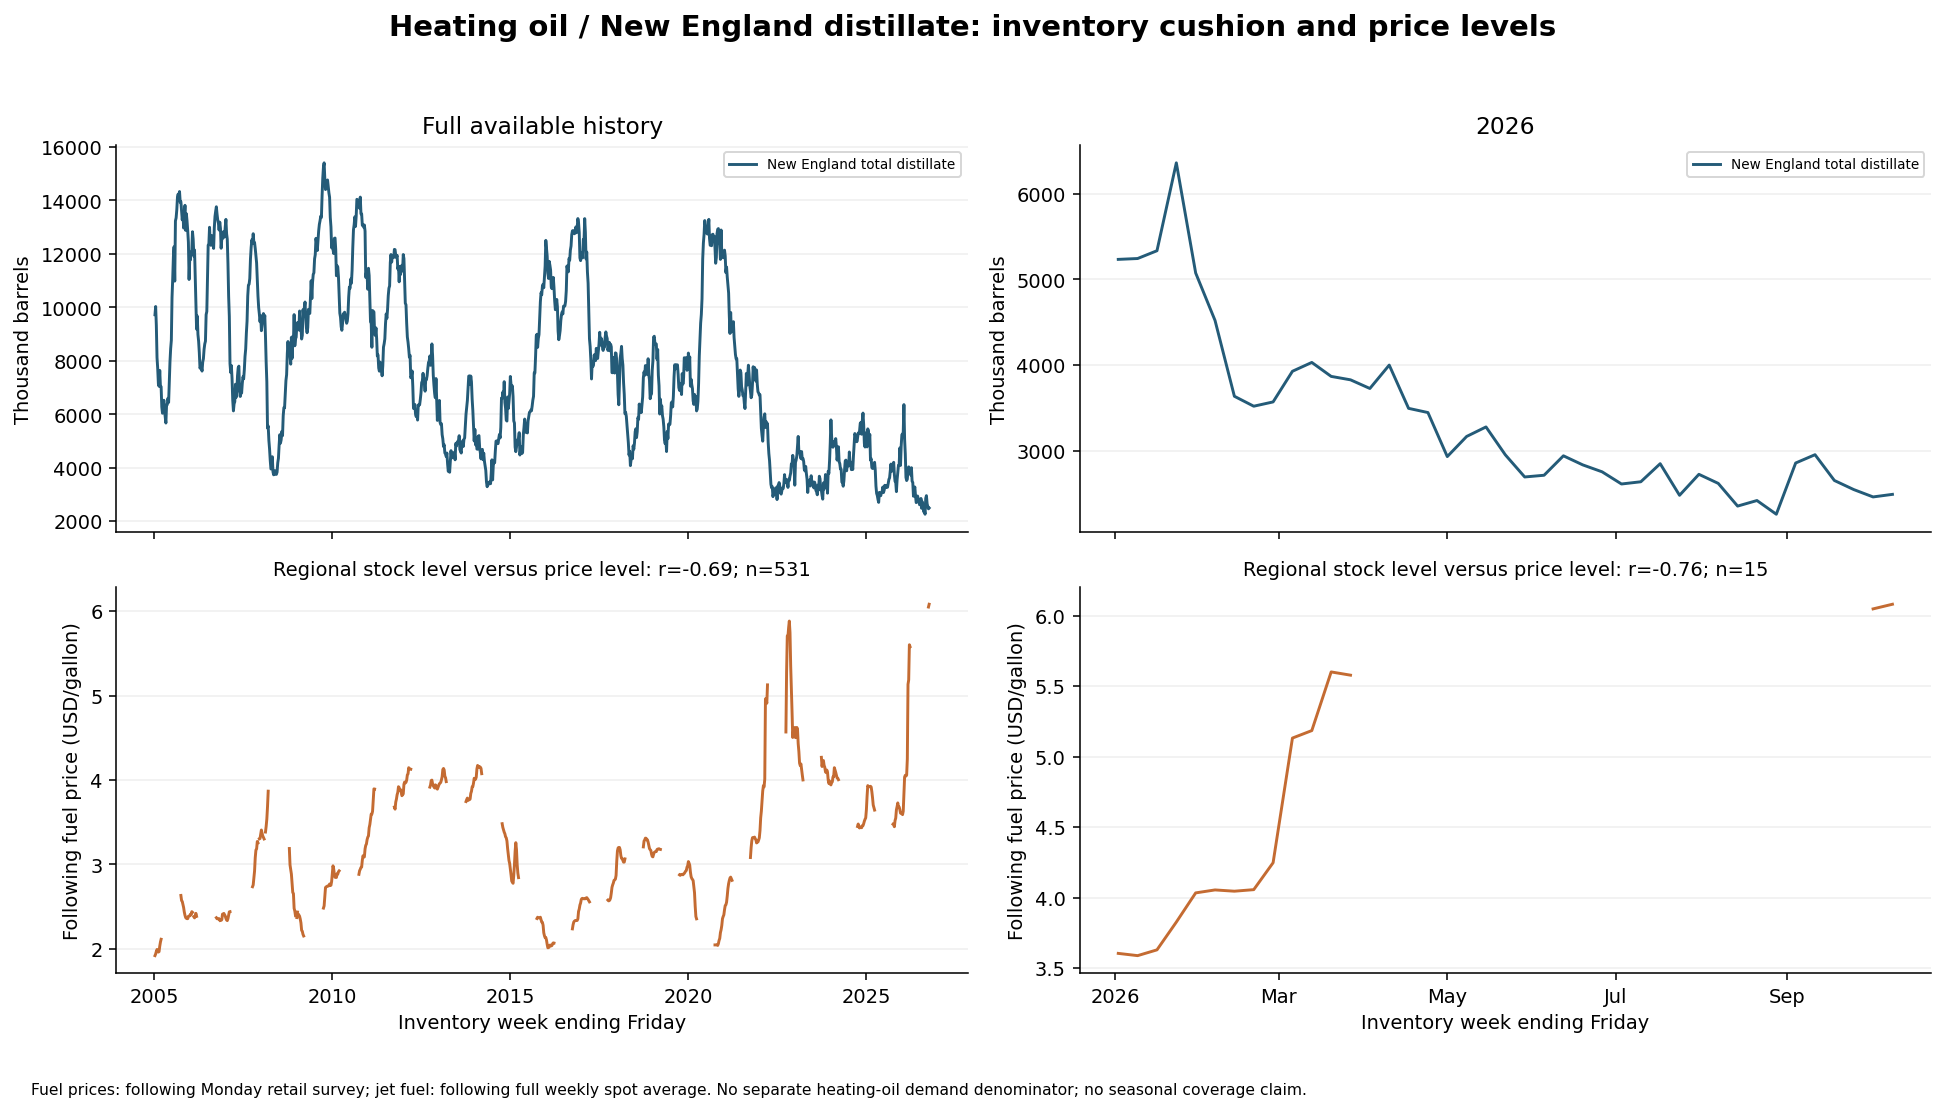

In [8]:
for fuel in charts.EVIDENCE_FUELS:
    charts.show_native(charts.coverage_price_panels(level_details, fuel))


## Correlations: distinguish the factor being tested
WTI prices, raw inventory levels, seasonal coverage deviations and future price changes are different variables. Below, every outcome is a following **price level**. Each coefficient has its own complete-pair count. Heating-season comparisons use fewer observations.

Large level correlations may reflect common trends and shared shocks. They do not establish that inventory reductions caused price increases, nor do they validate forecasts. The earlier future-change tests remain visible and must not be replaced by these level results.


In [9]:
display(level_correlations[["period", "fuel", "factor", "pearson_r",
    "paired_weeks", "first_inventory_week", "last_inventory_week"]].round({"pearson_r": 3}))


,period,fuel,factor,pearson_r,paired_weeks,first_inventory_week,last_inventory_week
0,Full history,Gasoline,WTI price level,0.874,1136,2005-01-07,2026-10-09
1,Full history,Gasoline,Inventory level,-0.268,1136,2005-01-07,2026-10-09
2,Full history,Gasoline,Seasonal coverage deviation (%),-0.316,876,2010-01-01,2026-10-09
3,Earlier analysis window,Gasoline,WTI price level,0.907,249,2022-01-07,2026-10-09
4,Earlier analysis window,Gasoline,Inventory level,-0.360,249,2022-01-07,2026-10-09
5,Earlier analysis window,Gasoline,Seasonal coverage deviation (%),-0.249,249,2022-01-07,2026-10-09
6,2026,Gasoline,WTI price level,0.915,41,2026-01-02,2026-10-09
7,2026,Gasoline,Inventory level,-0.845,41,2026-01-02,2026-10-09
8,2026,Gasoline,Seasonal coverage deviation (%),-0.812,41,2026-01-02,2026-10-09
9,Full history,Diesel / total distillate,WTI price level,0.781,1136,2005-01-07,2026-10-09


## Recent direction of inventories, consumption, coverage and prices
The following table uses the first and last complete paired observations within the fixed 2026 window for each product. Dates are included because jet-fuel averages and seasonal heating-oil surveys do not have identical available endpoints.

Inventory and price percentages are endpoint descriptions, not estimates of causal effects. Coverage can move differently from stock levels when consumption changes. Seasonal-gap change is in **percentage points**, not percent. A negative seasonal gap means a thinner cushion than the prior-five-year seasonal median.


In [10]:
recent_evidence = charts.recent_trend_evidence(level_details)
columns = ["fuel", "start_inventory_week", "end_inventory_week", "paired_weeks",
    "inventory_change_pct", "recent_daily_consumption_change_pct", "days_supply_change_pct",
    "seasonal_gap_start_pct", "seasonal_gap_end_pct",
    "wti_change_pct", "following_fuel_price_change_pct"]
rounded_evidence = recent_evidence.copy()
numeric_columns = rounded_evidence.select_dtypes(include="number").columns
rounded_evidence[numeric_columns] = rounded_evidence[numeric_columns].round(3)
display(rounded_evidence.reindex(columns=columns))
# All endpoint amounts are retained for audit, not just percentage changes.
display(rounded_evidence)


,fuel,start_inventory_week,end_inventory_week,paired_weeks,inventory_change_pct,recent_daily_consumption_change_pct,days_supply_change_pct,seasonal_gap_start_pct,seasonal_gap_end_pct,wti_change_pct,following_fuel_price_change_pct
0,Gasoline,2026-01-02,2026-10-09,41,-13.954,-0.115,-13.855,1.693,-1.582,68.370,54.900
1,Diesel / total distillate,2026-01-02,2026-10-09,41,-20.625,9.507,-27.515,9.810,-13.750,68.370,77.711
2,Jet fuel,2026-01-02,2026-10-02,40,-3.461,3.543,-6.765,10.893,-8.614,70.438,135.184
3,Heating oil / New England distillate,2026-01-02,2026-10-09,15,-52.407,NaN,NaN,NaN,NaN,68.370,68.682


,fuel,start_inventory_week,end_inventory_week,paired_weeks,inventory_start,inventory_end,inventory_change_pct,wti_start,wti_end,wti_change_pct,...,following_fuel_price_change_pct,recent_daily_consumption_start,recent_daily_consumption_end,recent_daily_consumption_change_pct,days_supply_start,days_supply_end,days_supply_change_pct,seasonal_gap_start_pct,seasonal_gap_end_pct,seasonal_gap_change_percentage_points
0,Gasoline,2026-01-02,2026-10-09,41,242036.0,208262.0,-13.954,57.54,96.88,68.370,...,54.900,8688.25,8678.25,-0.115,27.858,23.998,-13.855,1.693,-1.582,-3.274
1,Diesel / total distillate,2026-01-02,2026-10-09,41,129273.0,102611.0,-20.625,57.54,96.88,68.370,...,77.711,3629.00,3974.00,9.507,35.622,25.821,-27.515,9.810,-13.750,-23.560
2,Jet fuel,2026-01-02,2026-10-02,40,44028.0,42504.0,-3.461,57.54,98.07,70.438,...,135.184,1679.25,1738.75,3.543,26.219,24.445,-6.765,10.893,-8.614,-19.507
3,Heating oil / New England distillate,2026-01-02,2026-10-09,15,5234.0,2491.0,-52.407,57.54,96.88,68.370,...,68.682,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Correlation heatmaps of levels — full history and 2026
These matrices compare levels, not weekly price changes. Inventory-versus-price is shown separately from price-versus-price. Every cell includes its paired observation count; heating oil has seasonal coverage. The alignment is unchanged from the preceding section.


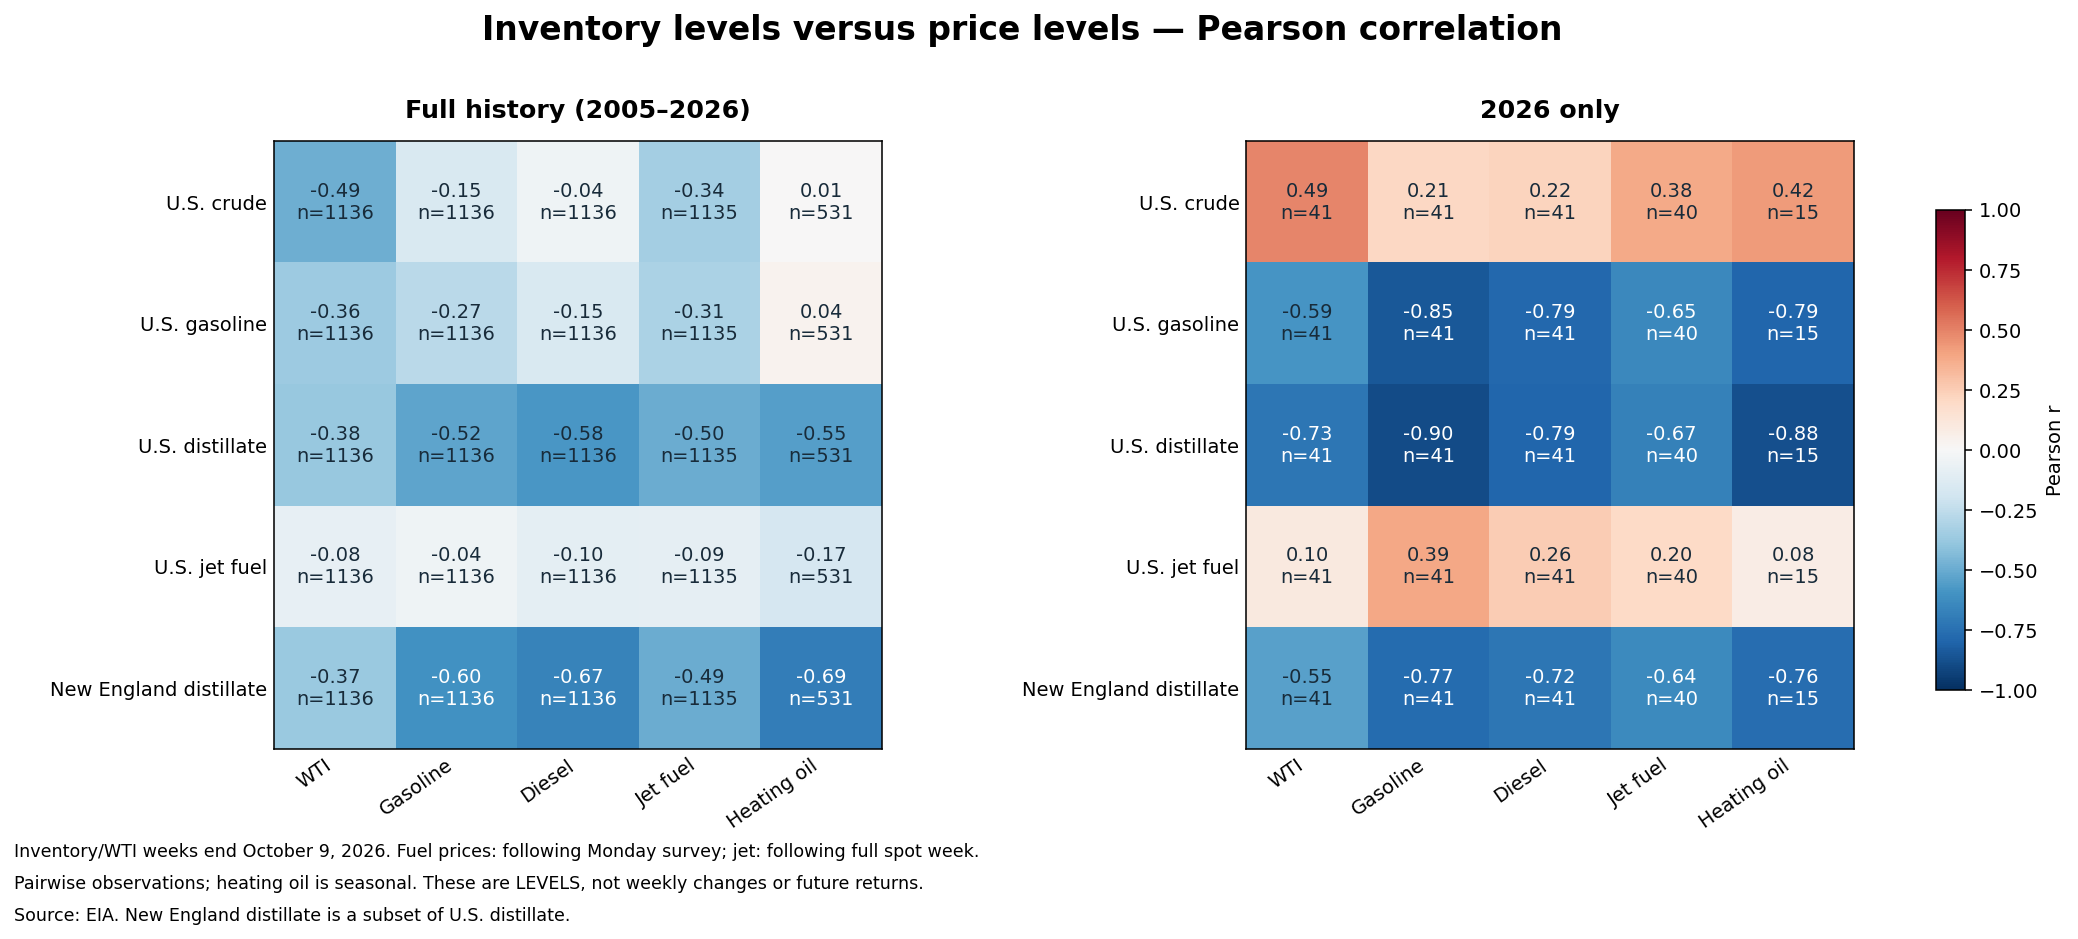

In [11]:
charts.show_native(charts.level_correlation_heatmaps(data, kind="inventory_price"))


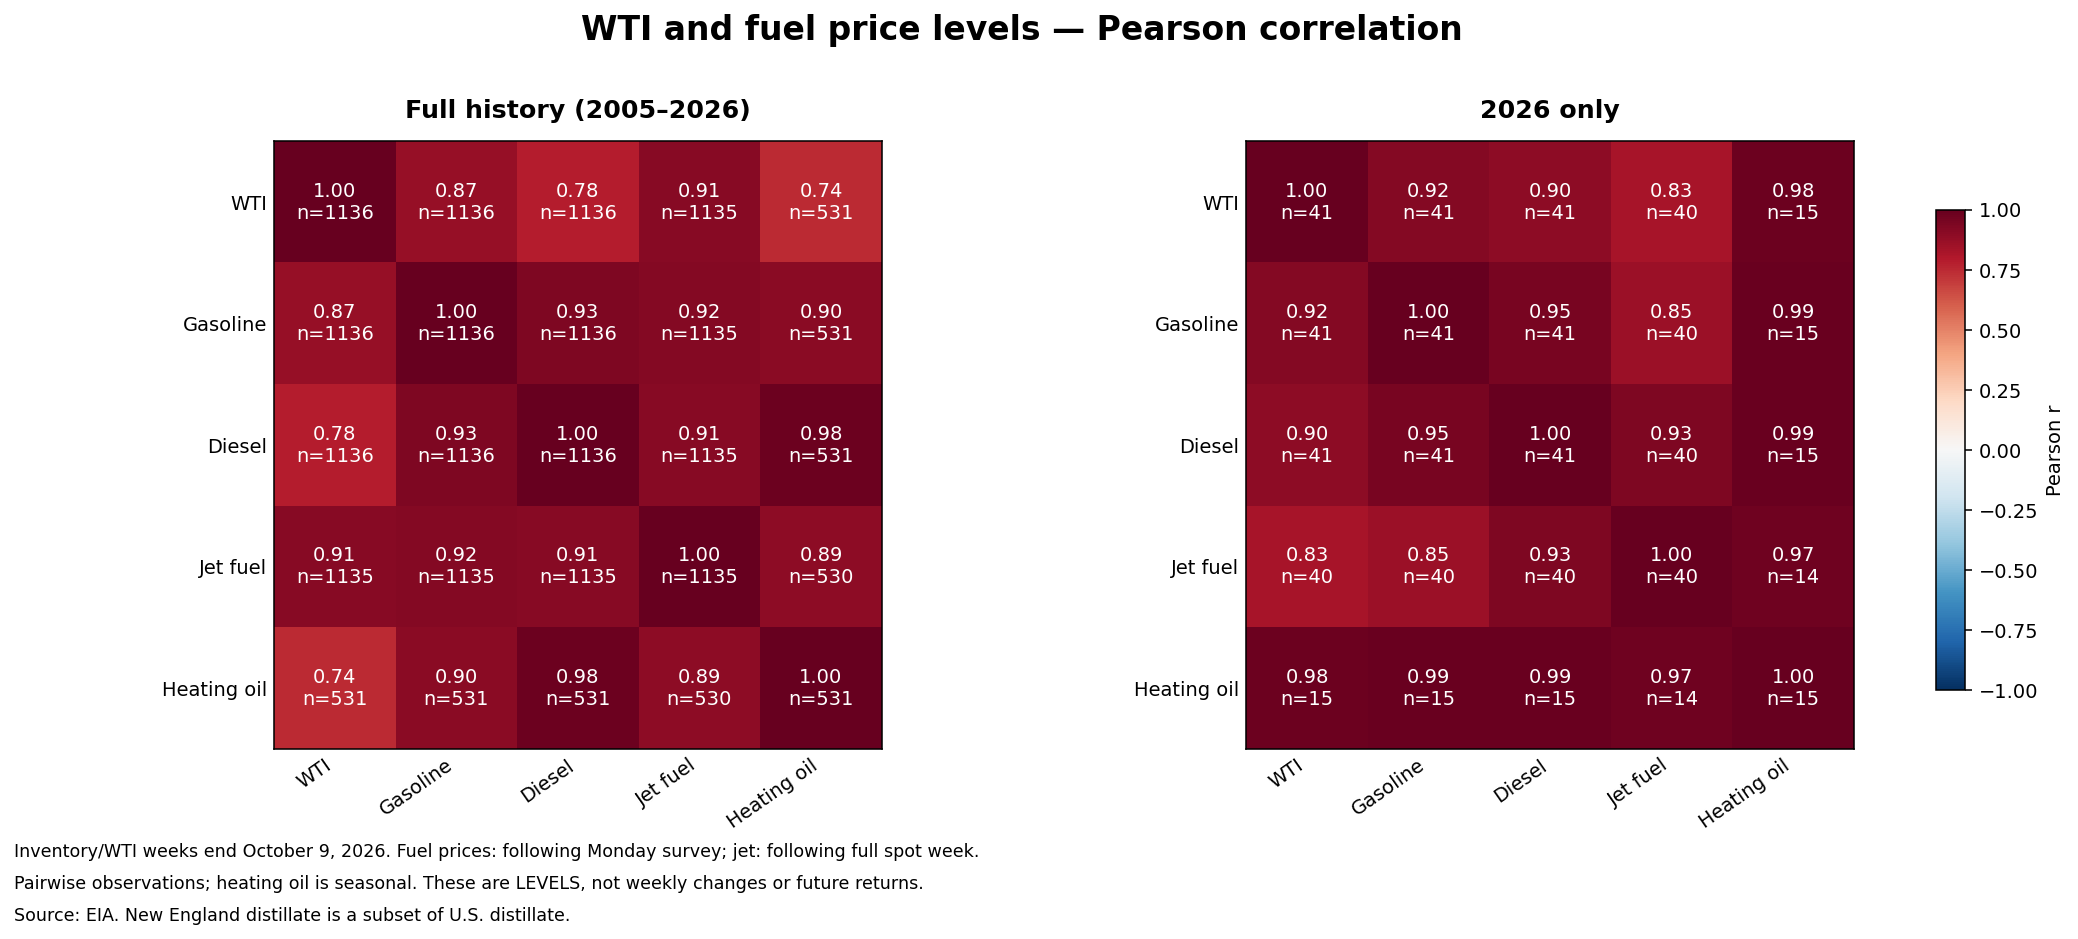

In [12]:
charts.show_native(charts.level_correlation_heatmaps(data, kind="price_price"))
